# 02 · Entrenamiento y evaluación (experimento auxiliar E4c, FRESA)

> **Qué demuestra y qué no.** DrBerry (enfermedades de arándano) sigue bloqueado por la API key de Roboflow, así que **no se entrenó ningún modelo de arándano**. Este notebook documenta el experimento **auxiliar** E4c: clasificación de imagen completa de 8 clases de fresa (`strawberry_traditional`, partición por grupos sin fugas). Sirve para validar el pipeline (datos, red residual, pérdidas, optimizadores, umbrales, análisis de falsos negativos y evaluación) que se aplicará a arándano. **Ninguna cifra de aquí es desempeño en arándano, en la finca ni en el robot.**
>
> **Sesgo conocido (notebook 01 §5.1):** la clase `strawberry_asymptomatic` proviene de otra fuente (Pérez-Borrero) que las enfermedades (Afzaal). La separación "enfermedad vs. sin síntomas" puede resolverse por la fuente. El análisis principal de falsos negativos es **entre enfermedades** (condicionado a que la imagen tiene enfermedad).

Los entrenamientos se ejecutan con `scripts/run_aux_experiments.sh` (GPU) y quedan registrados en `reports/experiments/<id>/`. Este notebook **lee** esos artefactos; `RUN_TRAINING = True` permite relanzar uno desde aquí.

## 1. Carga del conjunto aprobado y 2. comprobaciones de integridad

In [1]:
import sys, json, csv, warnings
from pathlib import Path
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
def _root():
    p = Path.cwd().resolve()
    for c in [p, *p.parents]:
        if (c / "pyproject.toml").exists() and (c / "src" / "berryvision").is_dir():
            return c
    raise FileNotFoundError
VISION = _root(); sys.path.insert(0, str(VISION / "src"))
from berryvision.manifest import read_manifest_csv
from berryvision.audit import sha256_file
from berryvision.training import selection as sel
from berryvision.training.metrics import (multiclass_summary, threshold_sweep, alert_scores, alert_curves,
                                          per_class_report, wilson_ci, predict_with_alert_threshold)
from berryvision.nbutils import save_panel
SHOW_PANELS = False
EXP = VISION / "reports/experiments"; FIG = VISION / "reports/figures"; PANELS = VISION / "reports/figures_local"
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 110})
meta = json.loads((VISION / "manifests/manifest_v1.meta.json").read_text(encoding="utf-8"))
assert sha256_file(VISION / "data/processed/manifest_v1.csv") == meta["manifest_sha256"], "el manifiesto cambió"
M = pd.DataFrame(read_manifest_csv(VISION / "data/processed/manifest_v1.csv"))
S = M[(M.source_id == "strawberry_traditional") & M.split.isin(["train", "val", "test"])]
assert not S[S.split != "train"].is_augmented.any() and (S.groupby("group_id").split.nunique() == 1).all()
print("manifiesto", meta["manifest_sha256"][:16], "verificado | sin aumentadas en val/test | grupos únicos por partición")
S.groupby(["split", "is_augmented"]).size().unstack(fill_value=0)

manifiesto 71f6055289b4e2b6 verificado | sin aumentadas en val/test | grupos únicos por partición


is_augmented,False,True
split,,
test,453,0
train,2122,1075
val,453,0


## 3. Transformaciones y 4. verificación de GPU

In [2]:
import torch, torchvision
base = yaml.safe_load((VISION / "configs/experiments/aux_strawberry/_base.yaml").read_text(encoding="utf-8"))
gpu = {"torch": torch.__version__, "torchvision": torchvision.__version__, "cuda_disponible": torch.cuda.is_available(),
       "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
       "memoria_GiB": round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2) if torch.cuda.is_available() else None}
display(pd.Series(gpu, name="entorno"))
pd.Series(base["augmentation"], name="aumentación (solo train)")

torch                                    2.14.1+cu126
torchvision                              0.29.1+cu126
cuda_disponible                                  True
gpu                NVIDIA GeForce RTX 4050 Laptop GPU
memoria_GiB                                       6.0
Name: entorno, dtype: object

hflip                             True
vflip                             True
rotation                            15
color_jitter    [0.2, 0.2, 0.15, 0.02]
jpeg_quality                  [60, 95]
blur_p                            0.15
Name: aumentación (solo train), dtype: object

Transformaciones: *letterbox* a `imgsz` (sin estirar; las imágenes ya son cuadradas 640×640) → aumentación moderada solo en train (volteos, rotación ±15°, color leve, compresión JPEG 60–95 que imita el MJPEG del robot, desenfoque leve) → tensor → **una única** normalización con las constantes de ImageNet (las del preentrenamiento; no se calculan con nuestros datos, así que no filtran información de val/test). Evaluación: solo *letterbox* + normalización.

## 5–9. Modelos, configuración, mini-batches, pérdidas y optimizadores

In [3]:
def load_runs():
    rows = []
    for d in sorted(EXP.glob("E4c_*")):
        if not (d / "run_info.json").exists():
            continue
        info = json.loads((d / "run_info.json").read_text(encoding="utf-8")); c = info["config"]
        rows.append({"id": info["id"], "modelo": c["model"]["name"] + (" (backbone congelado)" if c["model"].get("freeze_backbone") else ""),
                     "init": info["model"]["init"], "imgsz": c["model"]["imgsz"], "datos_train": "orig+aug" if c["data"].get("include_augmented", True) else "solo originales",
                     "n_train": info["data"]["n_train"], "pérdida": c["loss"]["name"], "optimizador": c["train"]["optimizer"], "lr": c["train"]["lr"],
                     "scheduler": c["train"]["scheduler"], "batch": c["train"]["batch_size"], "BN congelada": c["train"].get("freeze_bn", False),
                     "parámetros entrenables": info["model"]["params_trainable"], "épocas": info["fit"]["epochs_run"], "mejor época": info["fit"]["best_epoch"],
                     "min": round(info["fit"]["train_seconds"] / 60, 1), "pesos de clase": info["data"]["class_weights"]})
    return pd.DataFrame(rows).set_index("id")
R = load_runs(); R.drop(columns=["pesos de clase"])

,modelo,init,imgsz,datos_train,n_train,pérdida,optimizador,lr,scheduler,batch,BN congelada,parámetros entrenables,épocas,mejor época,min
id,,,,,,,,,,,,,,,
E4c_00_smallcnn_scratch,smallcnn,aleatoria,224,orig+aug,3197,ce,adamw,0.0010,cosine,64,False,390952,25,17,10.0
E4c_01_resnet18_linear_probe,resnet18 (backbone congelado),ImageNet,224,orig+aug,3197,ce,adamw,0.0010,cosine,64,False,4104,15,13,6.4
E4c_02_resnet18_adamw_ce,resnet18,ImageNet,224,orig+aug,3197,ce,adamw,0.0003,cosine,64,False,11180616,15,14,6.2
E4c_03_resnet18_sgd_ce,resnet18,ImageNet,224,orig+aug,3197,ce,sgd,0.0100,cosine,64,False,11180616,12,7,5.2
E4c_04_originals_ce,resnet18,ImageNet,224,solo originales,2122,ce,adamw,0.0003,cosine,64,False,11180616,15,15,5.1
E4c_05_originals_weighted_ce,resnet18,ImageNet,224,solo originales,2122,weighted_ce,adamw,0.0003,cosine,64,False,11180616,13,8,8.0
E4c_06_originals_focal,resnet18,ImageNet,224,solo originales,2122,focal,adamw,0.0003,cosine,64,False,11180616,15,15,7.2
E4c_07_imgsz384,resnet18,ImageNet,384,orig+aug,3197,ce,adamw,0.0003,cosine,32,False,11180616,15,14,18.4
E4c_08_freeze_bn,resnet18,ImageNet,224,orig+aug,3197,ce,adamw,0.0003,cosine,64,True,11171016,15,12,8.9


In [4]:
w = R["pesos de clase"].dropna()
classes = base["data"]["classes"]
pd.DataFrame({k: v for k, v in w.items()}, index=classes).round(3) if len(w) else "sin experimentos con pesos"

,E4c_05_originals_weighted_ce
strawberry_asymptomatic,0.431
strawberry_gray_mold,0.518
strawberry_flower_blossom_blight,1.178
strawberry_fruit_anthracnose_rot,2.584
strawberry_fruit_powdery_mildew,1.823
strawberry_leaf_angular_leafspot,0.568
strawberry_leaf_powdery_mildew,0.464
strawberry_leaf_spot,0.434


**Decisiones y por qué:**
- **Red residual preentrenada (ResNet-18)**: bloques residuales + BatchNorm, ImageNet como inicialización; con ~3 mil imágenes no se justifica una red profunda desde cero. Se compara con una **CNN pequeña sin residuales ni preentrenamiento** (referencia) y con un **linear probe** (backbone congelado) para medir cuánto aporta el ajuste fino.
- **Mini-batch 64** a 224 px (32 a 384 px) cabe en 6 GiB con AMP; `drop_last` en train evita lotes de 1 con BN; mezcla solo en train.
- **AdamW vs SGD+momentum (Nesterov)** con el mismo scheduler coseno con calentamiento de 1 época; *weight decay* 1e-4; *dropout* 0,2 en la cabeza; *early stopping* (paciencia 5) sobre validación.
- **Pérdidas** (solo con originales, donde el desbalance es real): CE, CE ponderada (w_c = N/(K·n_c), recortada a [0,25, 4] y normalizada a media 1, **calculada solo con train**) y Focal (γ=2).
- **Criterio de checkpoint**: recall macro de las clases de enfermedad en validación (desempate: pérdida de validación). Nunca el test.

## 10–11. Entrenamiento y curvas de aprendizaje

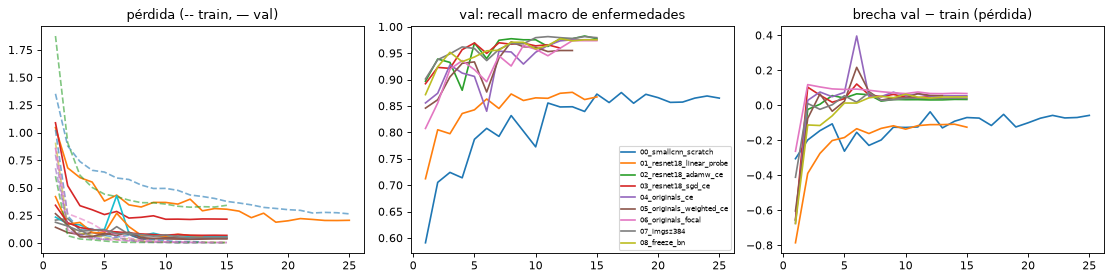

In [5]:
RUN_TRAINING = False   # True relanza un experimento (GPU); por defecto se leen los artefactos existentes
if RUN_TRAINING:
    import subprocess; subprocess.run([sys.executable, str(VISION / "scripts/train_classifier.py"), str(VISION / "configs/experiments/aux_strawberry/E4c_02_resnet18_adamw_ce.yaml")], check=True)
H = {i: pd.read_csv(EXP / i / "history.csv") for i in R.index}
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for i, h in H.items():
    axs[0].plot(h.epoch, h.train_loss, "--", alpha=.6); axs[0].plot(h.epoch, h.val_loss, label=i[4:])
    axs[1].plot(h.epoch, h.val_disease_macro_recall, label=i[4:])
    axs[2].plot(h.epoch, h.val_loss - h.train_loss, label=i[4:])
axs[0].set_title("pérdida (-- train, — val)"); axs[1].set_title("val: recall macro de enfermedades"); axs[2].set_title("brecha val − train (pérdida)")
axs[1].legend(fontsize=6); plt.tight_layout(); plt.savefig(FIG / "train_curves_all.png"); plt.show()

Cómo leer las curvas: la pérdida de train se mide con la red en modo entrenamiento (dropout y aumentación activos), por eso puede quedar **por encima** de la de validación sin indicar subajuste. Señales de sobreajuste = pérdida de validación que sube mientras la de train baja, o recall de validación que se estanca/cae; el *early stopping* guarda la mejor época de validación.

## Comparación de experimentos (solo validación) y selección

In [6]:
# Se LEE la selección congelada (no se recalcula: recalcular tras abrir test sería selección a posteriori)
if not (EXP / "selection.json").exists():
    import subprocess; subprocess.run([sys.executable, str(VISION / "scripts/select_experiment.py")], check=True)
selection = json.loads((EXP / "selection.json").read_text(encoding="utf-8"))
print("selección decidida:", selection["decided_at"], "| split:", selection["split_used"])
T = pd.DataFrame(selection["table"]).set_index("id")
cols = ["disease_cond_macro_recall", "disease_cond_min_recall", "disease_cond_worst_class", "val_macro_recall", "val_acc",
        "alert_threshold", "alert_fn", "alert_fp", "alerts_per_100", "val_ece", "gap_loss_best", "best_epoch", "train_min", "latency_ms"]
display(T[cols].sort_values("disease_cond_macro_recall", ascending=False).round(3))
SEL = selection["selected"]; print("Seleccionado con validación:", SEL)

selección decidida: 2026-10-24T02:17:49+00:00 | split: val


,disease_cond_macro_recall,disease_cond_min_recall,disease_cond_worst_class,val_macro_recall,val_acc,alert_threshold,alert_fn,alert_fp,alerts_per_100,val_ece,gap_loss_best,best_epoch,train_min,latency_ms
id,,,,,,,,,,,,,,
E4c_02_resnet18_adamw_ce,0.982,0.933,strawberry_fruit_anthracnose_rot,0.985,0.989,0.78,0,0,81.0,0.011,0.033,14,6.2,4.176
E4c_07_imgsz384,0.981,0.933,strawberry_fruit_anthracnose_rot,0.984,0.993,0.77,0,0,81.0,0.012,0.040,14,18.4,5.268
E4c_08_freeze_bn,0.977,0.933,strawberry_fruit_anthracnose_rot,0.980,0.989,0.86,0,0,81.0,0.010,0.040,12,8.9,38.550
E4c_04_originals_ce,0.975,0.933,strawberry_fruit_anthracnose_rot,0.978,0.987,0.89,0,0,81.0,0.017,0.053,15,5.1,4.137
E4c_06_originals_focal,0.974,0.933,strawberry_fruit_anthracnose_rot,0.977,0.984,0.87,0,0,81.0,0.027,0.067,15,7.2,3.401
E4c_05_originals_weighted_ce,0.971,0.915,strawberry_gray_mold,0.975,0.982,0.86,0,0,81.0,0.021,0.029,8,8.0,18.124
E4c_03_resnet18_sgd_ce,0.970,0.915,strawberry_gray_mold,0.973,0.980,0.86,0,0,81.0,0.013,0.060,7,5.2,3.241
E4c_01_resnet18_linear_probe,0.897,0.676,strawberry_gray_mold,0.891,0.918,0.39,0,0,81.0,0.041,-0.111,13,6.4,3.067
E4c_00_smallcnn_scratch,0.875,0.650,strawberry_fruit_powdery_mildew,0.891,0.918,0.90,0,0,81.0,0.040,-0.116,17,10.0,0.974


Seleccionado con validación: E4c_04_originals_ce


**Regla de selección** (fijada antes de ver resultados, `src/berryvision/training/selection.py`): (1) recall macro **condicionado entre enfermedades**, (2) peor recall por clase de enfermedad, (3) FN de alerta, (4) alertas por 100 imágenes, (5) latencia. No se usa la exactitud global.

In [7]:
def comp(ids, title):
    t = T.loc[[i for i in ids if i in T.index], ["disease_cond_macro_recall", "disease_cond_min_recall", "disease_cond_worst_class", "val_macro_recall", "val_ece"]]
    print(title); display(t.round(3))
comp(["E4c_00_smallcnn_scratch", "E4c_01_resnet18_linear_probe", "E4c_02_resnet18_adamw_ce"], "Referencia vs transferencia (CNN desde cero / linear probe / ajuste fino)")
comp(["E4c_02_resnet18_adamw_ce", "E4c_03_resnet18_sgd_ce"], "Optimizador (AdamW vs SGD+momentum), mismo scheduler")
comp(["E4c_04_originals_ce", "E4c_05_originals_weighted_ce", "E4c_06_originals_focal"], "Pérdidas con desbalance real (solo originales)")
comp(["E4c_02_resnet18_adamw_ce", "E4c_04_originals_ce"], "Aumentadas del autor en train vs solo originales")
comp(["E4c_02_resnet18_adamw_ce", "E4c_07_imgsz384"], "Resolución de entrada 224 vs 384")
comp(["E4c_02_resnet18_adamw_ce", "E4c_08_freeze_bn"], "BatchNorm ajustable vs estadísticas congeladas")

Referencia vs transferencia (CNN desde cero / linear probe / ajuste fino)


,disease_cond_macro_recall,disease_cond_min_recall,disease_cond_worst_class,val_macro_recall,val_ece
id,,,,,
E4c_00_smallcnn_scratch,0.875,0.650,strawberry_fruit_powdery_mildew,0.891,0.040
E4c_01_resnet18_linear_probe,0.897,0.676,strawberry_gray_mold,0.891,0.041
E4c_02_resnet18_adamw_ce,0.982,0.933,strawberry_fruit_anthracnose_rot,0.985,0.011


Optimizador (AdamW vs SGD+momentum), mismo scheduler


,disease_cond_macro_recall,disease_cond_min_recall,disease_cond_worst_class,val_macro_recall,val_ece
id,,,,,
E4c_02_resnet18_adamw_ce,0.982,0.933,strawberry_fruit_anthracnose_rot,0.985,0.011
E4c_03_resnet18_sgd_ce,0.970,0.915,strawberry_gray_mold,0.973,0.013


Pérdidas con desbalance real (solo originales)


...

,disease_cond_macro_recall,disease_cond_min_recall,disease_cond_worst_class,val_macro_recall,val_ece
id,,,,,
E4c_02_resnet18_adamw_ce,0.982,0.933,strawberry_fruit_anthracnose_rot,0.985,0.011
E4c_04_originals_ce,0.975,0.933,strawberry_fruit_anthracnose_rot,0.978,0.017


Resolución de entrada 224 vs 384


,disease_cond_macro_recall,disease_cond_min_recall,disease_cond_worst_class,val_macro_recall,val_ece
id,,,,,
E4c_02_resnet18_adamw_ce,0.982,0.933,strawberry_fruit_anthracnose_rot,0.985,0.011
E4c_07_imgsz384,0.981,0.933,strawberry_fruit_anthracnose_rot,0.984,0.012


BatchNorm ajustable vs estadísticas congeladas


,disease_cond_macro_recall,disease_cond_min_recall,disease_cond_worst_class,val_macro_recall,val_ece
id,,,,,
E4c_02_resnet18_adamw_ce,0.982,0.933,strawberry_fruit_anthracnose_rot,0.985,0.011
E4c_08_freeze_bn,0.977,0.933,strawberry_fruit_anthracnose_rot,0.980,0.010


## 12. Ajuste del umbral de alerta (solo validación)

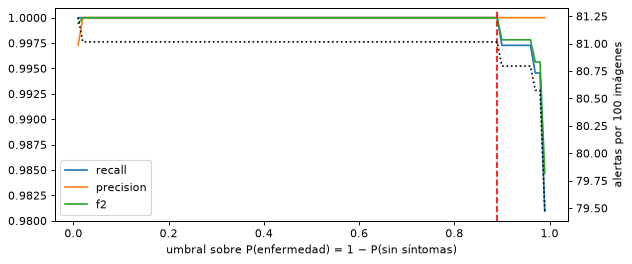

,feasible,threshold,recall,precision,fn,fp,alerts_per_100_images
max_f2,True,0.89,1.0,1.0,0,0,81.015453
recall>=0.95,True,0.99,0.980926,1.0,7,0,79.470199
recall>=0.98,True,0.99,0.980926,1.0,7,0,79.470199


In [8]:
th = json.loads((EXP / SEL / "val_thresholds.json").read_text(encoding="utf-8"))
sw = pd.DataFrame(th["sweep"])
fig, ax = plt.subplots(figsize=(8, 3.4))
for c in ["recall", "precision", "f2"]: ax.plot(sw.threshold, sw[c], label=c)
ax2 = ax.twinx(); ax2.plot(sw.threshold, sw.alerts_per_100_images, "k:", label="alertas/100"); ax2.set_ylabel("alertas por 100 imágenes")
ax.axvline(th["threshold"], color="r", ls="--"); ax.set_xlabel("umbral sobre P(enfermedad) = 1 − P(sin síntomas)"); ax.legend(loc="lower left")
plt.tight_layout(); plt.savefig(FIG / "threshold_sweep_selected.png"); plt.show()
pd.DataFrame({k: {c: v.get(c) for c in ["feasible", "threshold", "recall", "precision", "fn", "fp", "alerts_per_100_images"]} for k, v in th["rules"].items()}).T

El umbral se congela en validación (`val_thresholds.json`) antes de abrir test. **Advertencia:** por la confusión fuente-clase, este punto de operación binario no es trasladable a arándano; el procedimiento sí lo es.

## 13. Matrices de confusión (validación del modelo seleccionado)

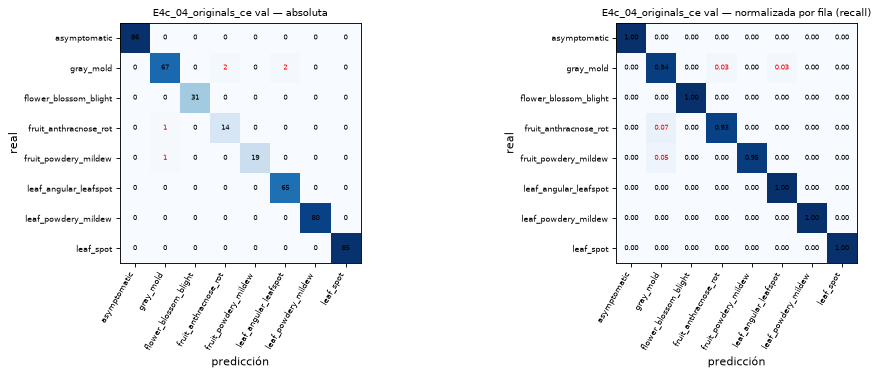

In [9]:
vm = json.loads((EXP / SEL / "val_metrics.json").read_text(encoding="utf-8"))
npz = np.load(EXP / SEL / "val_predictions.npz"); P, Y = npz["probs"], npz["labels"]
cls = vm["classes"]; short = [c.replace("strawberry_", "") for c in cls]; hi = cls.index(vm["healthy_class"])
def plot_cm(cm, labels, title, fn):
    cm = np.array(cm); norm = cm / cm.sum(1, keepdims=True).clip(1)
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
    for ax, mat, t in [(axs[0], cm, "absoluta"), (axs[1], norm, "normalizada por fila (recall)")]:
        ax.imshow(mat, cmap="Blues"); ax.set_title(f"{title} — {t}", fontsize=9)
        ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=7)
        ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=7); ax.set_xlabel("predicción"); ax.set_ylabel("real")
        for i in range(len(labels)):
            for j in range(len(labels)):
                ax.text(j, i, f"{mat[i, j]:.2f}" if mat is norm else int(mat[i, j]), ha="center", va="center", fontsize=6,
                        color="red" if (i != j and mat[i, j] > 0) else "black")
    plt.tight_layout(); plt.savefig(FIG / fn); plt.show()
plot_cm(vm["argmax"]["confusion"], short, f"{SEL} val", "confusion_val_selected.png")

Lectura: filas = clase real, columnas = predicción. **Celdas de mayor costo**: una enfermedad predicha como `asymptomatic` (columna `asymptomatic`, filas de enfermedad) → la alerta no se emitiría. Fuera de la diagonal entre enfermedades = alerta emitida con el diagnóstico equivocado (costo menor: se revisa, pero la información es engañosa).

## 14. ROC y Precision-Recall

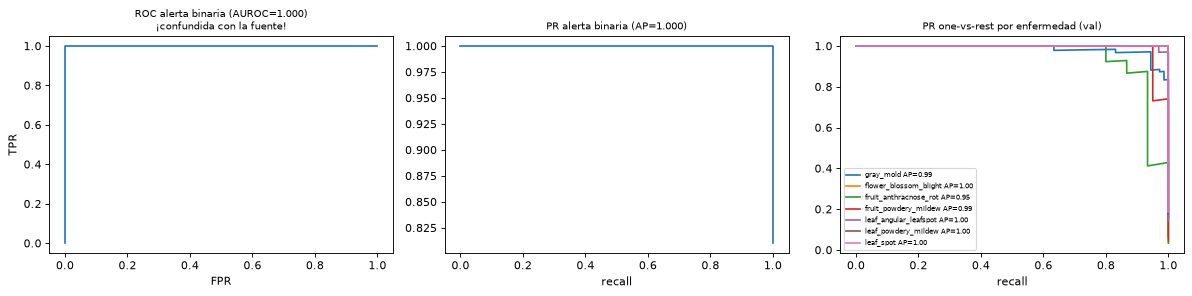

AUROC macro_ovr       0.9991
AUROC weighted_ovr    0.9994
AUROC micro           0.9997
mAP OvR macro         0.9901
ECE                   0.0173
dtype: float64

In [10]:
from sklearn.metrics import precision_recall_curve, roc_curve, average_precision_score
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
ac = vm["alert_curves"]
axs[0].plot(ac["roc"]["fpr"], ac["roc"]["tpr"]); axs[0].set_title(f"ROC alerta binaria (AUROC={ac['auroc']:.3f})\n¡confundida con la fuente!", fontsize=9); axs[0].set_xlabel("FPR"); axs[0].set_ylabel("TPR")
axs[1].plot(ac["pr"]["recall"], ac["pr"]["precision"]); axs[1].set_title(f"PR alerta binaria (AP={ac['ap']:.3f})", fontsize=9); axs[1].set_xlabel("recall")
for i, c in enumerate(cls):
    if i == hi: continue
    p, r, _ = precision_recall_curve((Y == i).astype(int), P[:, i]); axs[2].plot(r, p, label=f"{short[i]} AP={average_precision_score((Y == i).astype(int), P[:, i]):.2f}")
axs[2].set_title("PR one-vs-rest por enfermedad (val)", fontsize=9); axs[2].legend(fontsize=6); axs[2].set_xlabel("recall")
plt.tight_layout(); plt.savefig(FIG / "roc_pr_val_selected.png"); plt.show()
pd.Series({**{f"AUROC {k}": v for k, v in vm["argmax"]["auroc"].items()}, "mAP OvR macro": vm["argmax"]["map_ovr_macro"], "ECE": vm["argmax"]["calibration"]["ece"]}).round(4)

Definiciones: ROC/AP multiclase **one-vs-rest** por clase; *macro* = media simple entre clases, *weighted* = ponderada por soporte, *micro* = todas las decisiones binarias juntas. Con clases desbalanceadas en val (15 a 86 imágenes) la curva PR por clase es más informativa que el AUROC agregado.

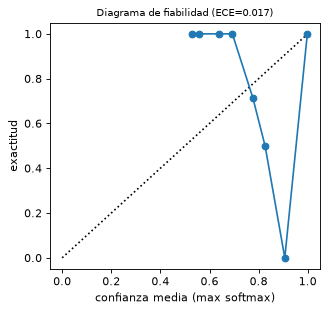

In [11]:
cal = pd.DataFrame([b for b in vm["argmax"]["calibration"]["bins"] if b["n"]])
fig, ax = plt.subplots(figsize=(4.2, 4)); ax.plot([0, 1], [0, 1], "k:"); ax.plot(cal.conf, cal.acc, "o-")
ax.set_xlabel("confianza media (max softmax)"); ax.set_ylabel("exactitud"); ax.set_title(f"Diagrama de fiabilidad (ECE={vm['argmax']['calibration']['ece']:.3f})", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "reliability_val_selected.png"); plt.show()

`confidence` es la salida softmax: aunque la ECE sea baja en este conjunto, **no** es una probabilidad de infección, y la calibración no se transfiere a otro dominio (ver §17, fuera de dominio).

## 15. Análisis de falsos negativos (validación)

In [12]:
rep = pd.DataFrame(vm["argmax"]["per_class"]).set_index("class")
rep["recall_IC95"] = rep.recall_ci95.apply(lambda v: f"[{v[0]:.2f}, {v[1]:.2f}]")
display(rep[["support", "tp", "fn", "fp", "recall", "recall_IC95", "precision", "specificity", "f1", "f2"]].round(3))
dc = sel.disease_conditional(P, Y, cls, hi)
dcr = pd.DataFrame(dc["per_class"]).set_index("class")
dcr["recall_IC95"] = dcr.recall_ci95.apply(lambda v: f"[{v[0]:.2f}, {v[1]:.2f}]")
print("Condicionado a enfermedad (análisis principal): macro-recall", round(dc["macro_recall"], 3), "| peor", round(dc["min_recall"], 3))
dcr[["support", "tp", "fn", "fp", "recall", "recall_IC95", "precision"]].round(3)

,support,tp,fn,fp,recall,recall_IC95,precision,specificity,f1,f2
class,,,,,,,,,,
strawberry_asymptomatic,86,86,0,0,1.000,"[0.96, 1.00]",1.000,1.000,1.000,1.000
strawberry_gray_mold,71,67,4,2,0.944,"[0.86, 0.98]",0.971,0.995,0.957,0.949
strawberry_flower_blossom_blight,31,31,0,0,1.000,"[0.89, 1.00]",1.000,1.000,1.000,1.000
strawberry_fruit_anthracnose_rot,15,14,1,2,0.933,"[0.70, 0.99]",0.875,0.995,0.903,0.921
strawberry_fruit_powdery_mildew,20,19,1,0,0.950,"[0.76, 0.99]",1.000,1.000,0.974,0.960
strawberry_leaf_angular_leafspot,65,65,0,2,1.000,"[0.94, 1.00]",0.970,0.995,0.985,0.994
strawberry_leaf_powdery_mildew,80,80,0,0,1.000,"[0.95, 1.00]",1.000,1.000,1.000,1.000
strawberry_leaf_spot,85,85,0,0,1.000,"[0.96, 1.00]",1.000,1.000,1.000,1.000


Condicionado a enfermedad (análisis principal): macro-recall 0.975 | peor 0.933


,support,tp,fn,fp,recall,recall_IC95,precision
class,,,,,,,
strawberry_gray_mold,71,67,4,2,0.944,"[0.86, 0.98]",0.971
strawberry_flower_blossom_blight,31,31,0,0,1.000,"[0.89, 1.00]",1.000
strawberry_fruit_anthracnose_rot,15,14,1,2,0.933,"[0.70, 0.99]",0.875
strawberry_fruit_powdery_mildew,20,19,1,0,0.950,"[0.76, 0.99]",1.000
strawberry_leaf_angular_leafspot,65,65,0,2,1.000,"[0.94, 1.00]",0.970
strawberry_leaf_powdery_mildew,80,80,0,0,1.000,"[0.95, 1.00]",1.000
strawberry_leaf_spot,85,85,0,0,1.000,"[0.96, 1.00]",1.000


In [13]:
pred = P.argmax(1)
img_ids = npz["image_ids"]; by_id = M.set_index("image_id")
fn_rows = []
for k in np.where((pred != Y) & (Y != hi))[0]:
    r = by_id.loc[img_ids[k]]
    fn_rows.append({"image_id": img_ids[k], "real": short[Y[k]], "predicho": short[pred[k]], "conf_pred": round(float(P[k].max()), 3),
                    "P(real)": round(float(P[k, Y[k]]), 3), "tipo": "ALERTA OMITIDA (→ sin síntomas)" if pred[k] == hi else "enfermedad equivocada",
                    "rel_path": r.rel_path})
FN = pd.DataFrame(fn_rows)
display(FN.drop(columns="rel_path").sort_values(["tipo", "real"]).head(40))
FN.groupby(["real", "predicho"]).size().rename("errores").sort_values(ascending=False).head(15)

,image_id,real,predicho,conf_pred,P(real),tipo
3,strawberry_traditional:79f1c60d0952,fruit_anthracnose_rot,gray_mold,0.992,0.005,enfermedad equivocada
5,strawberry_traditional:7b351c2d8878,fruit_powdery_mildew,gray_mold,0.899,0.067,enfermedad equivocada
0,strawberry_traditional:3d22aa83e0c7,gray_mold,leaf_angular_leafspot,0.914,0.009,enfermedad equivocada
1,strawberry_traditional:4a358f4d3916,gray_mold,fruit_anthracnose_rot,0.843,0.084,enfermedad equivocada
2,strawberry_traditional:46108e8aadf4,gray_mold,leaf_angular_leafspot,0.800,0.197,enfermedad equivocada
4,strawberry_traditional:834ce20cc1fa,gray_mold,fruit_anthracnose_rot,0.760,0.226,enfermedad equivocada


real                   predicho             
gray_mold              leaf_angular_leafspot    2
                       fruit_anthracnose_rot    2
fruit_powdery_mildew   gray_mold                1
fruit_anthracnose_rot  gray_mold                1
Name: errores, dtype: int64

In [14]:
items = [{"rel_path": r.rel_path, "title": f"{r.real[:12]}→{r.predicho[:12]} {r.conf_pred}"} for r in FN.itertuples()][:30]
p = save_panel(items, VISION, PANELS / f"fn_val_{SEL}.jpg", draw_boxes=False)
if SHOW_PANELS:
    from IPython.display import Image as _I, display as _d; _d(_I(filename=str(p)))
print("panel local de errores en enfermedades:", p.relative_to(VISION))

panel local de errores en enfermedades:

 reports\figures_local\fn_val_E4c_04_originals_ce.jpg


**Revisión de los errores** (sobre el panel local): los fallos se concentran en pares de clases visualmente cercanas (p. ej. oídio en fruto frente a otras pudriciones de fruto; manchas foliares entre sí). Las causas probables son lesiones pequeñas o tempranas, fotos lejanas, oclusión y la escasez de originales de algunas clases (*anthracnose*: 15 en val). **Ningún error se declara "etiqueta incorrecta" sin revisión agronómica.**

## 16. Visualización de predicciones (TP, FP, FN, TN)

In [15]:
def panel(mask, name, n=18):
    idx = np.where(mask)[0][:n]
    its = [{"rel_path": by_id.loc[img_ids[k]].rel_path, "title": f"r:{short[Y[k]][:10]} p:{short[pred[k]][:10]} {P[k].max():.2f}"} for k in idx]
    return save_panel(its, VISION, PANELS / f"{name}_{SEL}.jpg", draw_boxes=False)
alert_pred = alert_scores(P, hi) >= th["threshold"]; alert_true = Y != hi
paths = {"TP alerta": panel(alert_pred & alert_true & (pred == Y), "tp"), "FP alerta": panel(alert_pred & ~alert_true, "fp"),
         "FN alerta": panel(~alert_pred & alert_true, "fn_alert"), "TN": panel(~alert_pred & ~alert_true, "tn")}
pd.Series({k: str(v.relative_to(VISION)) for k, v in paths.items()}, name="paneles locales")

TP alerta     reports\figures_local\tp_E4c_04_originals_ce.jpg
FP alerta     reports\figures_local\fp_E4c_04_originals_ce.jpg
FN alerta    reports\figures_local\fn_alert_E4c_04_original...
TN            reports\figures_local\tn_E4c_04_originals_ce.jpg
Name: paneles locales, dtype: str

## 17. Evaluación final en test (una sola vez, con umbral congelado)

Test abierto: 2026-10-24T02:19:19+00:00 | motivo de selección: regla lexicográfica de selection.py sobre validación (selection.json 2026-10-24T02:17:49Z); empate con E4c_02 resuelto por latencia (diferencia de ruido)


exactitud                      0.9845
balanced acc / macro recall    0.9589
AUROC macro OvR                0.9993
ECE                            0.0090
alerta@0.89 recall             0.9973
alerta FN                      1.0000
alerta FP                      0.0000
Name: test, dtype: float64

TEST condicionado a enfermedad: macro-recall 0.953 | peor 0.75


,support,tp,fn,recall,IC95,precision
class,,,,,,
strawberry_gray_mold,71,71,0,1.000,"[0.95, 1.00]",0.934
strawberry_flower_blossom_blight,31,31,0,1.000,"[0.89, 1.00]",1.000
strawberry_fruit_anthracnose_rot,15,14,1,0.933,"[0.70, 0.99]",0.933
strawberry_fruit_powdery_mildew,20,15,5,0.750,"[0.53, 0.89]",1.000
strawberry_leaf_angular_leafspot,65,65,0,1.000,"[0.94, 1.00]",1.000
strawberry_leaf_powdery_mildew,80,80,0,1.000,"[0.95, 1.00]",0.988
strawberry_leaf_spot,85,84,1,0.988,"[0.94, 1.00]",1.000


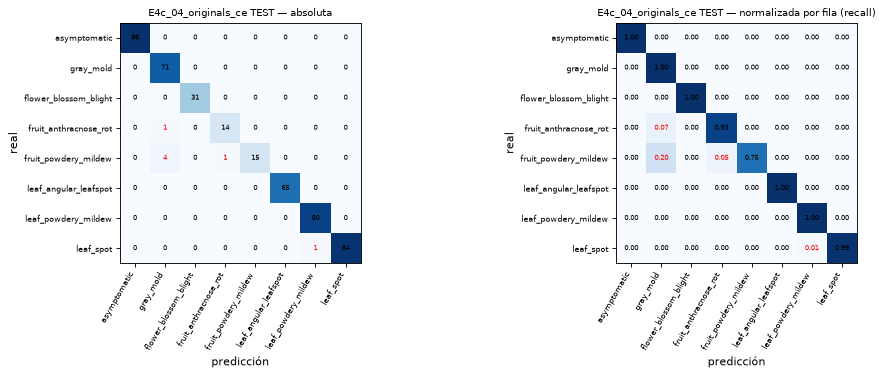

,n,mean_max_prob,frac_max_prob_ge_0.9,frac_alert_at_threshold,predicted_class_counts
plantvillage_blueberry_healthy,1502,0.715946,0.195073,0.161119,"{'strawberry_asymptomatic': 799, 'strawberry_f..."
plantdoc_blueberry,117,0.661937,0.17094,0.769231,"{'strawberry_asymptomatic': 7, 'strawberry_gra..."


In [16]:
tm_path = EXP / SEL / "test_metrics.json"
if tm_path.exists():
    tm = json.loads(tm_path.read_text(encoding="utf-8"))
    print("Test abierto:", tm["opened_at"], "| motivo de selección:", tm["selected_because"])
    a = tm["alert_at_frozen_threshold"]
    display(pd.Series({"exactitud": tm["argmax"]["accuracy"], "balanced acc / macro recall": tm["argmax"]["macro_recall"],
                       "AUROC macro OvR": tm["argmax"]["auroc"].get("macro_ovr"), "ECE": tm["argmax"]["calibration"]["ece"],
                       f"alerta@{tm['frozen_threshold']:.2f} recall": a["recall"], "alerta FN": a["fn"], "alerta FP": a["fp"]}, name="test").round(4))
    tnpz = np.load(EXP / SEL / "test_predictions.npz")
    tdc = sel.disease_conditional(tnpz["probs"], tnpz["labels"], cls, hi)
    t = pd.DataFrame(tdc["per_class"]).set_index("class"); t["IC95"] = t.recall_ci95.apply(lambda v: f"[{v[0]:.2f}, {v[1]:.2f}]")
    print("TEST condicionado a enfermedad: macro-recall", round(tdc["macro_recall"], 3), "| peor", round(tdc["min_recall"], 3))
    display(t[["support", "tp", "fn", "recall", "IC95", "precision"]].round(3))
    plot_cm(tm["argmax"]["confusion"], short, f"{SEL} TEST", "confusion_test_selected.png")
    ood = json.loads((EXP / SEL / "ood_blueberry_check.json").read_text(encoding="utf-8"))
    display(pd.DataFrame(ood).T)
else:
    print("Test aún no evaluado: ejecute scripts/evaluate_final.py tras congelar la selección.")

**Fuera de dominio (arándano).** El modelo de fresa se aplicó a hojas de arándano (PlantVillage, PlantDoc), que **no pertenecen a ninguna de sus clases**. La fracción de predicciones con confianza ≥ 0,9 y la de alertas emitidas miden su exceso de confianza ante imágenes ajenas: un clasificador cerrado **siempre** responde una de sus clases. Para el sistema real hace falta un mecanismo de "no sé / requiere inspección" (umbral de confianza, detección de fuera de distribución o una clase *otros* con datos que la definan).

## 18. Conclusiones y limitaciones

Ver `reports/experiment_report.md`, `reports/error_analysis.md` y `reports/metrics_per_class.md` (generados con estas mismas salidas). En resumen:

1. El pipeline (manifiesto → grupos sin fuga → red residual → umbral en validación → test congelado → análisis de FN) funciona de extremo a extremo con GPU.
2. En fresa, **"enfermedad vs. sin síntomas" está confundida con la fuente**: sus métricas casi perfectas **no** prueban reconocimiento de síntomas.
3. Las confusiones **entre enfermedades** sí son informativas y muestran qué clases se omiten más.
4. Nada de esto valida Botrytis, Alternaria ni trips en arándano, ni el desempeño con la cámara del X2 Ultra.